# 03 – DistilBERT, 512 token, 3 epoch

A 02-höz képest csak a max. hossz (256 → 512) és az epochszám (2 → 3) változik.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import set_seed

from common import FIG_DIR, METRICS_DIR, RESULTS_DIR, SEED, labels_for, load_split, results_table
from train_utils import (RunConfig, count_tokens, describe_device, evaluate_5to3, load_info, load_tokenizer,
                         run_task)

CFG = RunConfig(name="distilbert_512_3ep", max_len=512, epochs=3, per_device_batches=(8, 4), eval_batch_size=16)
BASE_RUN = "distilbert"
set_seed(SEED)
describe_device()

torch 2.15.0+cu132 | NVIDIA GeForce GTX 1660 | free GPU memory: 5.0 / 6.0 GB


## 1. Adat és lefedettség

In [2]:
split = load_split()
test_df = split["test"]
tokenizer = load_tokenizer(CFG)
n_tokens = pd.Series(count_tokens(tokenizer, pd.concat(split.values())["text"]))

coverage = pd.DataFrame({
    f"max {L} token": {"levágott értékelések aránya": f"{(n_tokens > L).mean():.1%}",
                       "a teljes szövegmennyiség látott része": f"{n_tokens.clip(upper=L).sum() / n_tokens.sum():.1%}"}
    for L in (256, 512)
})
coverage

,max 256 token,max 512 token
levágott értékelések aránya,20.1%,4.2%
a teljes szövegmennyiség látott része,80.8%,95.6%


## 2. Tanítás

Effektív batch 16 (8 × 2 gradiens-akkumuláció).

### 5 osztály

Map:   0%|          | 0/14400 [00:00<?, ? examples/s]

Map:   0%|          | 0/14400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Mentett modell betöltése: E:\Tanulmányok\Óbudai Egyetem\MSc - Data Science\3. szemeszter\Mesterséges intelligencia alkalmazási területei\Féléves feladat\yelp-sentiment-distilbert\models\distilbert_512_3ep_5class


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

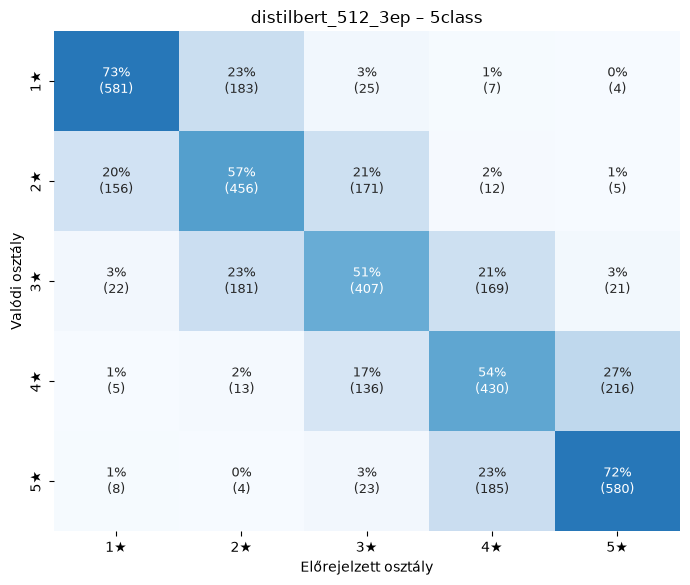

distilbert_512_3ep / 5class: accuracy=0.6135  macro-F1=0.6135


In [3]:
proba5, info5 = run_task(CFG, "5class", split, tokenizer)

### 3 osztály

Map:   0%|          | 0/14400 [00:00<?, ? examples/s]

Map:   0%|          | 0/14400 [00:00<?, ? examples/s]

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Map:   0%|          | 0/4000 [00:00<?, ? examples/s]

Mentett modell betöltése: E:\Tanulmányok\Óbudai Egyetem\MSc - Data Science\3. szemeszter\Mesterséges intelligencia alkalmazási területei\Féléves feladat\yelp-sentiment-distilbert\models\distilbert_512_3ep_3class


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

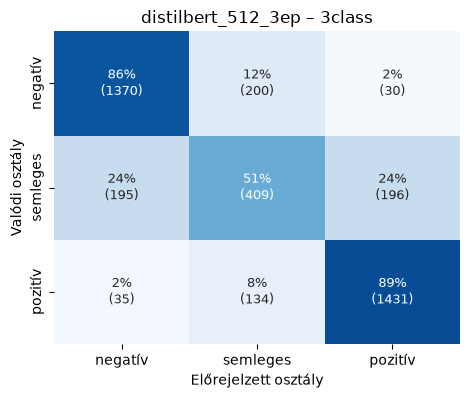

distilbert_512_3ep / 3class: accuracy=0.8025  macro-F1=0.7550


In [4]:
proba3, info3 = run_task(CFG, "3class", split, tokenizer)

### 5 osztályos előrejelzés összevonása 3 osztályra

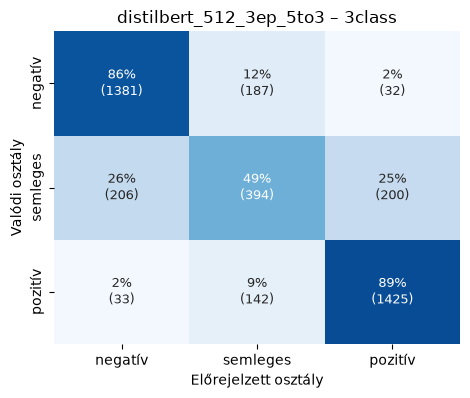

distilbert_512_3ep_5to3 / 3class: accuracy=0.8000  macro-F1=0.7501


In [5]:
evaluate_5to3(CFG.name, proba5, test_df)

## 3. Validációs macro-F1 és költség

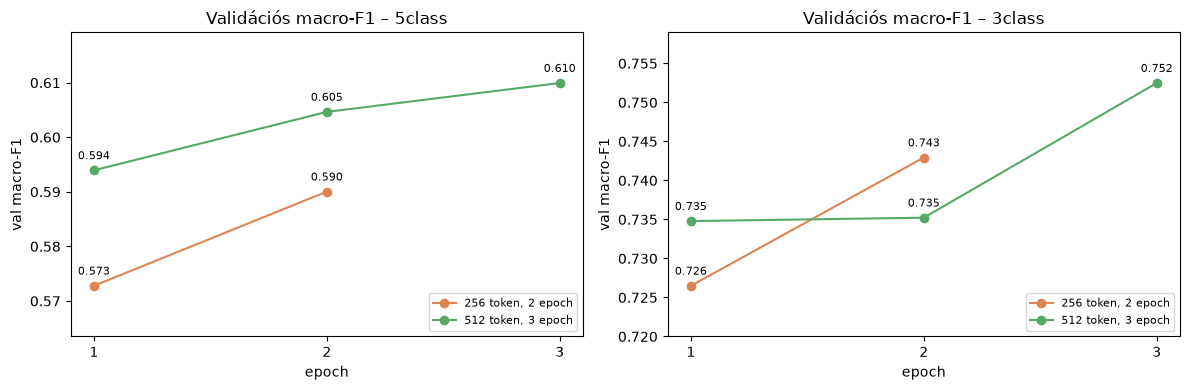

,"256 token, 2 epoch – 5class","512 token, 3 epoch – 5class","256 token, 2 epoch – 3class","512 token, 3 epoch – 3class"
tanítási idő (perc),9.0,16.9,9.0,17.0
legjobb val macro-F1,0.59,0.6099,0.7429,0.7525
batch (eszközönként x akkumuláció),16 x 1,8 x 2,16 x 1,8 x 2
GPU-memória csúcs (GB),–,2.32,–,2.32


In [6]:
RUN_LABELS = {BASE_RUN: "256 token, 2 epoch", CFG.name: "512 token, 3 epoch"}
RUN_COLORS = {BASE_RUN: "#DD8452", CFG.name: "#55A868"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, task in zip(axes, ("5class", "3class")):
    for run in (BASE_RUN, CFG.name):
        hist = pd.DataFrame(load_info(run, task)["log_history"])
        ev = hist.dropna(subset=["eval_macro_f1"])
        ax.plot(ev["epoch"], ev["eval_macro_f1"], "o-", color=RUN_COLORS[run], label=RUN_LABELS[run])
        for _, r in ev.iterrows():
            ax.annotate(f"{r['eval_macro_f1']:.3f}", (r["epoch"], r["eval_macro_f1"]),
                        textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
    ax.set(title=f"Validációs macro-F1 – {task}", xlabel="epoch", ylabel="val macro-F1", xticks=[1, 2, 3])
    ax.margins(y=0.25)
    ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "val_f1_256_vs_512.png", dpi=200, bbox_inches="tight")
plt.show()

cost = pd.DataFrame({
    f"{RUN_LABELS[run]} – {task}": {
        "tanítási idő (perc)": round(i["train_seconds"] / 60, 1),
        "legjobb val macro-F1": round(i["best_val_macro_f1"], 4),
        "batch (eszközönként x akkumuláció)": f"{i['per_device_batch_size']} x {i['gradient_accumulation_steps']}",
        "GPU-memória csúcs (GB)": round(i["peak_gpu_memory_gb"], 2) if i.get("peak_gpu_memory_gb") else "–",
    }
    for task in ("5class", "3class") for run in (BASE_RUN, CFG.name) for i in [load_info(run, task)]
})
cost

## 4. Összevetés

In [7]:
summary = results_table()
summary.to_csv(RESULTS_DIR / "summary.csv", index=False, encoding="utf-8")
display(summary.style.format({c: "{:.3f}" for c in summary.columns if c not in ("model", "task")}))

s = summary.set_index(["task", "model"])
rows = {}
for task in ("5class", "3class"):
    for ref in ("tfidf_logreg", BASE_RUN):
        d = (s.loc[(task, CFG.name)] - s.loc[(task, ref)])[["accuracy", "macro_f1"]] * 100
        rows[(task, f"vs. {ref}")] = d
delta = pd.DataFrame(rows).T.round(1)
delta.columns = ["Δ accuracy (%-pont)", "Δ macro-F1 (%-pont)"]
delta

,model,task,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,majority,3class,0.400,0.133,0.333,0.190,0.229
1,tfidf_logreg_5to3,3class,0.767,0.719,0.697,0.698,0.752
2,tfidf_logreg,3class,0.772,0.721,0.708,0.710,0.761
3,distilbert_5to3,3class,0.789,0.741,0.737,0.739,0.786
4,distilbert,3class,0.793,0.748,0.744,0.745,0.791
5,distilbert_512_3ep_5to3,3class,0.800,0.752,0.749,0.750,0.797
6,distilbert_512_3ep,3class,0.802,0.757,0.754,0.755,0.800
7,majority,5class,0.200,0.040,0.200,0.067,0.067
8,tfidf_logreg,5class,0.561,0.558,0.561,0.559,0.559
9,distilbert,5class,0.605,0.609,0.605,0.606,0.606


Δ accuracy (%-pont)  Δ macro-F1 (%-pont)
5class vs. tfidf_logreg                  5.2                  5.4
       vs. distilbert                    0.9                  0.7
3class vs. tfidf_logreg                  3.0                  4.5
       vs. distilbert                    0.9                  1.0

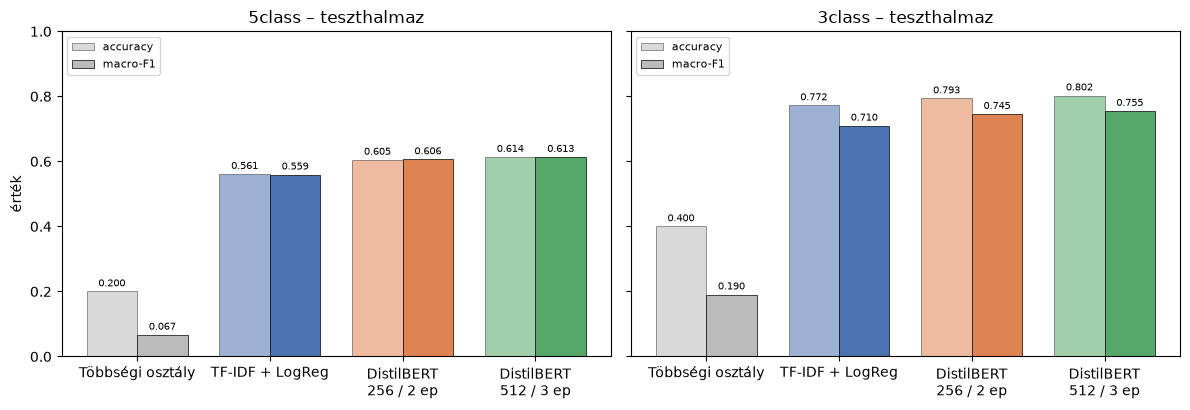

In [8]:
MODEL_NAMES = {"majority": "Többségi osztály", "tfidf_logreg": "TF-IDF + LogReg",
               "distilbert": "DistilBERT\n256 / 2 ep", CFG.name: "DistilBERT\n512 / 3 ep"}
COLORS = {"majority": "#BBBBBB", "tfidf_logreg": "#4C72B0", "distilbert": "#DD8452", CFG.name: "#55A868"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, task in zip(axes, ("5class", "3class")):
    sub = summary[summary["task"] == task].set_index("model")
    order = [m for m in MODEL_NAMES if m in sub.index]
    x = np.arange(len(order))
    for j, metric in enumerate(("accuracy", "macro_f1")):
        vals = sub.loc[order, metric].to_numpy()
        bars = ax.bar(x + (j - 0.5) * 0.38, vals, width=0.38,
                      color=[COLORS[m] for m in order], alpha=1 if j == 1 else 0.55,
                      edgecolor="black", linewidth=0.5, label="macro-F1" if j == 1 else "accuracy")
        ax.bar_label(bars, fmt="%.3f", fontsize=7, padding=2)
    ax.set_xticks(x, [MODEL_NAMES[m] for m in order])
    ax.set(title=f"{task} – teszthalmaz", ylim=(0, 1))
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("érték")
fig.tight_layout()
fig.savefig(FIG_DIR / "model_comparison_all.png", dpi=200, bbox_inches="tight")
plt.show()

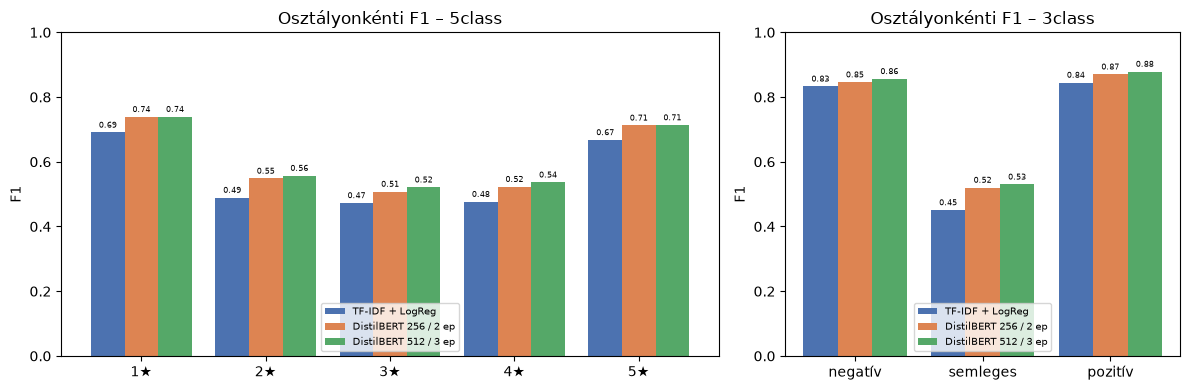

model            tfidf_logreg  distilbert  distilbert_512_3ep  \
task   class                                                    
5class 1★               0.690       0.739               0.739   
       2★               0.489       0.548               0.557   
       3★               0.473       0.508               0.521   
       4★               0.477       0.523               0.536   
       5★               0.667       0.712               0.713   
3class negatív          0.833       0.846               0.856   
       semleges         0.451       0.520               0.530   
       pozitív          0.845       0.870               0.879   

model            Δ 512/3 vs 256/2  
task   class                       
5class 1★                   0.000  
       2★                   0.009  
       3★                   0.013  
       4★                   0.014  
       5★                   0.001  
3class negatív              0.010  
       semleges             0.010  
       pozitív              0.008

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [5, 3]})
per_class_rows = []
models = ("tfidf_logreg", "distilbert", CFG.name)
w = 0.27
for ax, task in zip(axes, ("5class", "3class")):
    labels = labels_for(task)
    x = np.arange(len(labels))
    for j, model in enumerate(models):
        m = json.loads((METRICS_DIR / f"{model}_{task}.json").read_text(encoding="utf-8"))
        f1s = [m["per_class"][lab]["f1"] for lab in labels]
        per_class_rows += [{"task": task, "model": model, "class": lab, "f1": f} for lab, f in zip(labels, f1s)]
        bars = ax.bar(x + (j - 1) * w, f1s, width=w, color=COLORS[model], label=MODEL_NAMES[model].replace("\n", " "))
        ax.bar_label(bars, fmt="%.2f", fontsize=6, padding=2)
    ax.set_xticks(x, labels)
    ax.set(title=f"Osztályonkénti F1 – {task}", ylim=(0, 1), ylabel="F1")
    ax.legend(loc="lower center", fontsize=7)
fig.tight_layout()
fig.savefig(FIG_DIR / "per_class_f1_all.png", dpi=200, bbox_inches="tight")
plt.show()

per_class = pd.DataFrame(per_class_rows).pivot_table(index=["task", "class"], columns="model", values="f1", sort=False)
per_class = per_class[list(models)]
per_class["Δ 512/3 vs 256/2"] = per_class[CFG.name] - per_class["distilbert"]
per_class.round(3)

### Pontosság rövid és hosszú értékeléseken

In [10]:
test_tokens = count_tokens(tokenizer, test_df["text"])
is_long = test_tokens > 256

rows = []
for task in ("5class", "3class"):
    for model in ("tfidf_logreg", "distilbert", CFG.name):
        pred = pd.read_csv(RESULTS_DIR / "predictions" / f"{model}_{task}.csv")
        for name, mask in (("≤ 256 token", ~is_long), ("> 256 token", is_long)):
            rows.append({"task": task, "csoport": f"{name} (n={mask.sum()})", "model": model,
                         "accuracy": pred.loc[mask, "correct"].mean()})
by_length = pd.DataFrame(rows).pivot_table(index=["task", "csoport"], columns="model", values="accuracy", sort=False)
by_length = by_length[["tfidf_logreg", "distilbert", CFG.name]]
by_length.to_csv(RESULTS_DIR / "accuracy_by_length.csv", encoding="utf-8")
by_length.round(3)

model                        tfidf_logreg  distilbert  distilbert_512_3ep
task   csoport                                                           
5class ≤ 256 token (n=3196)         0.564       0.621               0.621
       > 256 token (n=804)          0.550       0.539               0.583
3class ≤ 256 token (n=3196)         0.773       0.808               0.809
       > 256 token (n=804)          0.767       0.735               0.775